In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding='latin1')

In [3]:
X = df[["QUANTITYORDERED", "SALES"]]

In [4]:
x_scaled = StandardScaler().fit_transform(X)

In [5]:
wcss = []

In [6]:
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(x_scaled)
    wcss.append(km.inertia_)

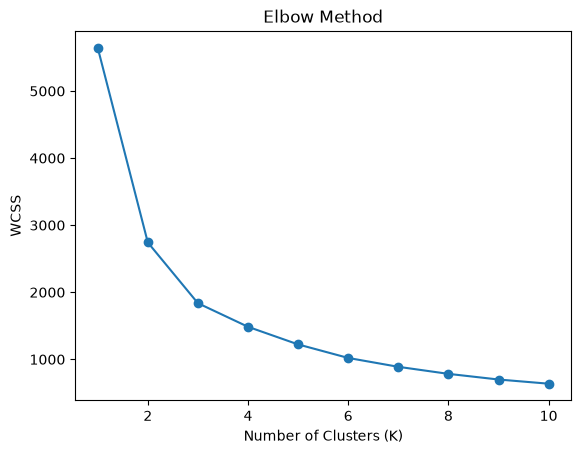

In [7]:
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [8]:
k = 3
model = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(x_scaled)

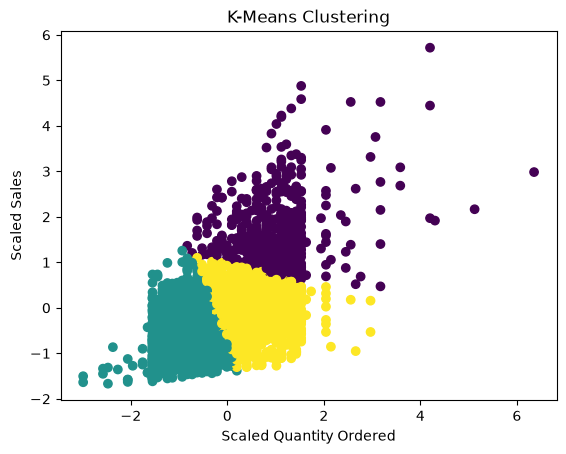

In [9]:
plt.scatter(x_scaled[:, 0], x_scaled[:, 1], c=df["Cluster"])
plt.xlabel("Scaled Quantity Ordered")
plt.ylabel("Scaled Sales")
plt.title("K-Means Clustering")
plt.show()

In [10]:
print("Number of clusters:", k)
print(df[["QUANTITYORDERED", "SALES", "Cluster"]].head())

Number of clusters: 3
   QUANTITYORDERED    SALES  Cluster
0               30  2871.00        1
1               34  2765.90        2
2               41  3884.34        2
3               45  3746.70        2
4               49  5205.27        0
